# Single-stock risk analysis
**Henri Mertens · HW2 Part 2**

Run from the homework directory after `01_data_cleaning.ipynb` has created `data/data.db`'s
`ohlc_hw_cleaned` table. Change the next cell to select a stock and historical window, or inject its
parameters with Papermill. The default June–November 2024 window matches the assignment's six-complete-month
example. All database access in this notebook is read-only.

The report uses **adjusted close** throughout. Prices and returns are never extrapolated to fill missing
history. Calculations retain fractions; percentages below are display formatting.

In [1]:
ticker = 'AAPL'
start_date = '2024-06-01'
end_date = '2024-11-30'
db_path = 'data/data.db'

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


## 2.1 Parameters and input checks
Dates must be ISO `YYYY-MM-DD`, the start cannot follow the end, and the database must already exist.
An unknown ticker or a window with no supplied observations raises a clear error rather than producing
an empty report. A short but nonempty history is displayed with unavailable statistics marked `N/A`.

In [3]:
from pathlib import Path
from datetime import date
import re
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display
import scrapbook as sb

TRADING_DAYS = 252
RISK_FREE_RATE = 0.02
VOL_WINDOW = 20
MA_WINDOW = 50
COLORS = {'green': '#19825b', 'red': '#c94555', 'pink': '#f7c6cd',
          'blue': '#345d88', 'gray': '#89929b', 'ink': '#243444'}

def validate_inputs(ticker_value, start_value, end_value, path_value):
    """Validate a stock identifier, strict ISO dates, and an existing local database path."""
    if not isinstance(ticker_value, str):
        raise ValueError('ticker must be a string.')
    symbol = ticker_value.strip().upper()
    if not re.fullmatch(r'[A-Z0-9][A-Z0-9.\-]*', symbol):
        raise ValueError('ticker must be a nonempty stock symbol, for example AAPL or BRK.B.')
    parsed = []
    for name, value in [('start_date', start_value), ('end_date', end_value)]:
        if not isinstance(value, str) or not re.fullmatch(r'\d{4}-\d{2}-\d{2}', value):
            raise ValueError(f'{name} must be an ISO YYYY-MM-DD string.')
        try:
            parsed.append(date.fromisoformat(value))
        except ValueError as error:
            raise ValueError(f'{name} is not a valid calendar date: {value}') from error
    if parsed[0] > parsed[1]:
        raise ValueError('start_date must not follow end_date.')
    path = Path(path_value).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError('Database not found. Run from the homework directory, or set db_path explicitly.')
    return symbol, parsed[0].isoformat(), parsed[1].isoformat(), path

ticker, start_date, end_date, database_path = validate_inputs(ticker, start_date, end_date, db_path)

## 2.2 Load the cleaned history
Only the requested stock and dates are queried. The report discloses requested dates, actual coverage,
observation count and any repairs/review flags inherited from cleaning. These review flags are context;
they do not automatically exclude a return from analysis.

In [4]:
def load_stock_data(path, symbol, start, end):
    """Read a cleaned stock window and its full supplied coverage without modifying SQLite."""
    connection = sqlite3.connect(Path(path).resolve().as_uri() + '?mode=ro', uri=True)
    try:
        connection.execute('PRAGMA query_only = ON')
        if not connection.execute(
            "SELECT 1 FROM sqlite_master WHERE type='table' AND name='ohlc_hw_cleaned'"
        ).fetchone():
            raise ValueError('Run 01_data_cleaning.ipynb first: ohlc_hw_cleaned is absent.')
        supplied = connection.execute(
            'SELECT MIN(ts), MAX(ts) FROM ohlc_hw_cleaned WHERE ticker = ?', (symbol,)
        ).fetchone()
        if supplied[0] is None:
            raise ValueError(f'{symbol} is not present in ohlc_hw_cleaned.')
        frame = pd.read_sql_query(
            'SELECT ts, ticker, adj_close, volume, adj_close_repaired, return_outlier_review '
            'FROM ohlc_hw_cleaned WHERE ticker = ? AND ts >= ? AND ts <= ? ORDER BY ts',
            connection, params=(symbol, start, end)
        )
    finally:
        connection.close()
    if frame.empty:
        raise ValueError(f'{symbol} has no observations in {start} to {end}; supplied history is {supplied[0]} to {supplied[1]}.')
    frame['ts'] = pd.to_datetime(frame['ts'], format='%Y-%m-%d', errors='raise')
    if frame['ts'].duplicated().any():
        raise ValueError('Duplicate dates found in cleaned data; rerun cleaning and investigate.')
    if not np.isfinite(frame['adj_close']).all() or not frame['adj_close'].gt(0).all():
        raise ValueError('Adjusted prices must be positive and finite.')
    return frame.set_index('ts'), supplied

stock, supplied_history = load_stock_data(database_path, ticker, start_date, end_date)
actual_start = stock.index.min().date().isoformat()
actual_end = stock.index.max().date().isoformat()
print(f'{ticker} from {start_date} to {end_date}: {len(stock):,} trading days')
print(f'Actual observations: {actual_start} to {actual_end}.')
print(f'Full supplied ticker history: {supplied_history[0]} to {supplied_history[1]}.')
coverage_notes = []
if start_date < supplied_history[0]:
    coverage_notes.append('The supplied history starts after the requested start; earlier prices are unavailable.')
if end_date > supplied_history[1]:
    coverage_notes.append('The supplied history ends before the requested end; later prices are unavailable.')
if len(stock) < VOL_WINDOW + 1:
    coverage_notes.append('Fewer than 21 prices: a 20-return rolling volatility estimate is unavailable.')
if len(stock) < MA_WINDOW:
    coverage_notes.append('Fewer than 50 prices: the 50-day moving average is unavailable.')
if len(stock) < 3:
    coverage_notes.append('Fewer than two returns: sample volatility and Sharpe ratio are unavailable.')
for note in coverage_notes:
    print('Coverage note:', note)
print('Adjusted-price repairs in window:', int(stock.adj_close_repaired.sum()))
print('Raw-return review flags in window:', int(stock.return_outlier_review.sum()))
print('First observations:')
display(stock.head())
print('Last observations:')
display(stock.tail())

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual observations: 2024-06-03 to 2024-10-18.
Full supplied ticker history: 1980-12-12 to 2024-10-18.
Coverage note: The supplied history ends before the requested end; later prices are unavailable.
Adjusted-price repairs in window: 7
Raw-return review flags in window: 0
First observations:


,ticker,adj_close,volume,adj_close_repaired,return_outlier_review
ts,,,,,
2024-06-03,AAPL,193.81,50080539,0,0
2024-06-04,AAPL,194.13,47471445,0,0
2024-06-05,AAPL,195.64,54156785,0,0
2024-06-06,AAPL,194.26,41181753,0,0
2024-06-07,AAPL,196.66,53103912,0,0


Last observations:


,ticker,adj_close,volume,adj_close_repaired,return_outlier_review
ts,,,,,
2024-10-14,AAPL,231.30,39882100,0,0
2024-10-15,AAPL,233.85,64751400,0,0
2024-10-16,AAPL,231.78,34082240,0,0
2024-10-17,AAPL,232.15,32993810,0,0
2024-10-18,AAPL,235.00,45441281,0,0


## 2.3 Calculate risk metrics

For adjusted price $P_t$, the daily log return is $r_t=\log(P_t/P_{t-1})$.
Volatility is the sample standard deviation of the latest 20 returns, multiplied by $\sqrt{252}$.
The first observation has no return, so 20 returns require at least 21 prices.

Drawdown is $P_t/\max_{s\le t} P_s-1$: it measures the fall below the running peak **inside this report window**.
It can recover to zero. Maximum drawdown is the most negative value of that series.

The course's Sharpe approximation is $(252\bar r-0.02)/(s_r\sqrt{252})$.
It uses a 2% annual risk-free rate and daily log returns. Insufficient or numerically zero sample
volatility yields `NaN` (displayed as `N/A`). No warm-up values are filled with zero.

In [5]:
def validated_returns(returns):
    """Keep defined returns, requiring them to be finite; do not turn missing values into zeros."""
    values = pd.to_numeric(returns, errors='raise').dropna().astype(float)
    if not np.isfinite(values).all():
        raise ValueError('Returns must be finite wherever defined.')
    return values

def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns from positive finite adjusted-close prices."""
    values = pd.to_numeric(prices, errors='raise').astype(float)
    if not np.isfinite(values).all() or not values.gt(0).all():
        raise ValueError('Prices must be positive and finite; no implicit price fill is allowed.')
    return np.log(values / values.shift(1))

def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Annualize rolling sample standard deviations, requiring a complete window of returns."""
    if not isinstance(window, int) or window < 2:
        raise ValueError('window must be an integer of at least two.')
    validated_returns(returns)
    return returns.rolling(window=window, min_periods=window).std(ddof=1) * np.sqrt(TRADING_DAYS)

def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running peak; its minimum is maximum drawdown."""
    values = pd.to_numeric(prices, errors='raise').astype(float)
    if not np.isfinite(values).all() or not values.gt(0).all():
        raise ValueError('Prices must be positive and finite.')
    return values / values.cummax() - 1

def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Use the course annualized log-return approximation; undefined ratios return NaN."""
    values = validated_returns(returns)
    if not np.isfinite(risk_free_rate):
        raise ValueError('risk_free_rate must be finite.')
    if len(values) < 2:
        return np.nan
    sample_std = values.std(ddof=1)
    if not np.isfinite(sample_std) or sample_std <= 1e-12:
        return np.nan
    return float((values.mean() * TRADING_DAYS - risk_free_rate) / (sample_std * np.sqrt(TRADING_DAYS)))

def summarize_stock(prices, returns, drawdown):
    """Return the ten required metrics as unformatted fractions, with NaN for unavailable values."""
    values = validated_returns(returns)
    n = len(values)
    up = values.loc[values.gt(0)]
    down = values.loc[values.lt(0)]
    return {
        'Total Return': float(prices.iloc[-1] / prices.iloc[0] - 1),
        'Annualized Return': float(np.expm1(values.sum() * TRADING_DAYS / n)) if n else np.nan,
        'Annualized Volatility': float(values.std(ddof=1) * np.sqrt(TRADING_DAYS)) if n >= 2 else np.nan,
        'Sharpe Ratio': calculate_sharpe_ratio(returns, RISK_FREE_RATE),
        'Maximum Drawdown': float(drawdown.min()),
        'Best Day': float(values.max()) if n else np.nan,
        'Worst Day': float(values.min()) if n else np.nan,
        'Positive Days': float(values.gt(0).sum() / n) if n else np.nan,
        'Average Up Day': float(up.mean()) if len(up) else np.nan,
        'Average Down Day': float(down.mean()) if len(down) else np.nan
    }

analysis = stock.copy()
analysis['log_return'] = calculate_returns(analysis['adj_close'])
analysis['rolling_volatility'] = calculate_volatility(analysis['log_return'], VOL_WINDOW)
analysis['moving_average_50'] = analysis['adj_close'].rolling(MA_WINDOW, min_periods=MA_WINDOW).mean()
analysis['drawdown'] = calculate_max_drawdown(analysis['adj_close'])
summary_metrics = summarize_stock(analysis.adj_close, analysis.log_return, analysis.drawdown)
mean_rolling_volatility = float(analysis.rolling_volatility.mean())
print('Defined daily log returns:', int(analysis.log_return.notna().sum()))
print('Available 20-return volatility estimates:', int(analysis.rolling_volatility.notna().sum()))
display(analysis[['adj_close', 'log_return', 'rolling_volatility', 'drawdown']].tail())

Defined daily log returns: 96
Available 20-return volatility estimates: 77


,adj_close,log_return,rolling_volatility,drawdown
ts,,,,
2024-10-14,231.30,0.016346,0.242503,-0.013856
2024-10-15,233.85,0.010964,0.243942,-0.002984
2024-10-16,231.78,-0.008891,0.241973,-0.011810
2024-10-17,232.15,0.001595,0.206097,-0.010232
2024-10-18,235.00,0.012202,0.209521,0.000000


### Small numerical checks
A known price path checks that drawdown can recover, that log returns compound to the total price
ratio, and that a complete rolling window starts only after enough returns. Separate examples verify
sample standard deviation, the course Sharpe formula, zero-volatility handling and the denominator
for positive days (zero-return days are included).

In [6]:
example_prices = pd.Series([100.0, 120.0, 90.0, 110.0, 130.0])
example_returns = calculate_returns(example_prices)
np.testing.assert_allclose(calculate_max_drawdown(example_prices), [0, 0, -0.25, 110/120 - 1, 0])
np.testing.assert_allclose(np.exp(example_returns.dropna().sum()), 1.3)
known_returns = pd.Series([np.nan, -0.01, 0.0, 0.01])
known_vol = calculate_volatility(known_returns, window=3)
assert known_vol.iloc[:3].isna().all()
np.testing.assert_allclose(known_vol.iloc[3], 0.01 * np.sqrt(252))
np.testing.assert_allclose(calculate_sharpe_ratio(known_returns), -0.02 / (0.01 * np.sqrt(252)))
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.0, 0.0, 0.0])))
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01])))
short_prices = pd.Series([100.0, 110.0, 110.0])
short_returns = calculate_returns(short_prices)
short_summary = summarize_stock(short_prices, short_returns, calculate_max_drawdown(short_prices))
np.testing.assert_allclose(short_summary['Positive Days'], 0.5)
assert np.isnan(short_summary['Average Down Day'])
assert calculate_volatility(short_returns).isna().all()
single_price = pd.Series([100.0])
single_summary = summarize_stock(single_price, calculate_returns(single_price), calculate_max_drawdown(single_price))
assert single_summary['Total Return'] == 0 and np.isnan(single_summary['Sharpe Ratio'])
assert np.isnan(single_summary['Best Day'])
# Actual report consistency, including preservation of the initial warm-up gaps.
assert analysis.log_return.iloc[:1].isna().all()
assert analysis.rolling_volatility.iloc[:VOL_WINDOW].isna().all()
assert analysis.moving_average_50.iloc[:MA_WINDOW - 1].isna().all()
assert analysis.drawdown.le(1e-12).all()
np.testing.assert_allclose(np.expm1(analysis.log_return.dropna().sum()), summary_metrics['Total Return'])
print('Numerical and short-history checks passed.')

Numerical and short-history checks passed.


## 2.4 Visual report
Price segments use the ending day's rolling-volatility classification: red above the report mean,
green at or below it, and gray while a complete rolling estimate is unavailable. This is retrospective
coloring. The moving average uses 50 observed prices within the requested window.
The drawdown shading becomes darker toward deeper drawdowns; its marked minimum is the maximum drawdown.

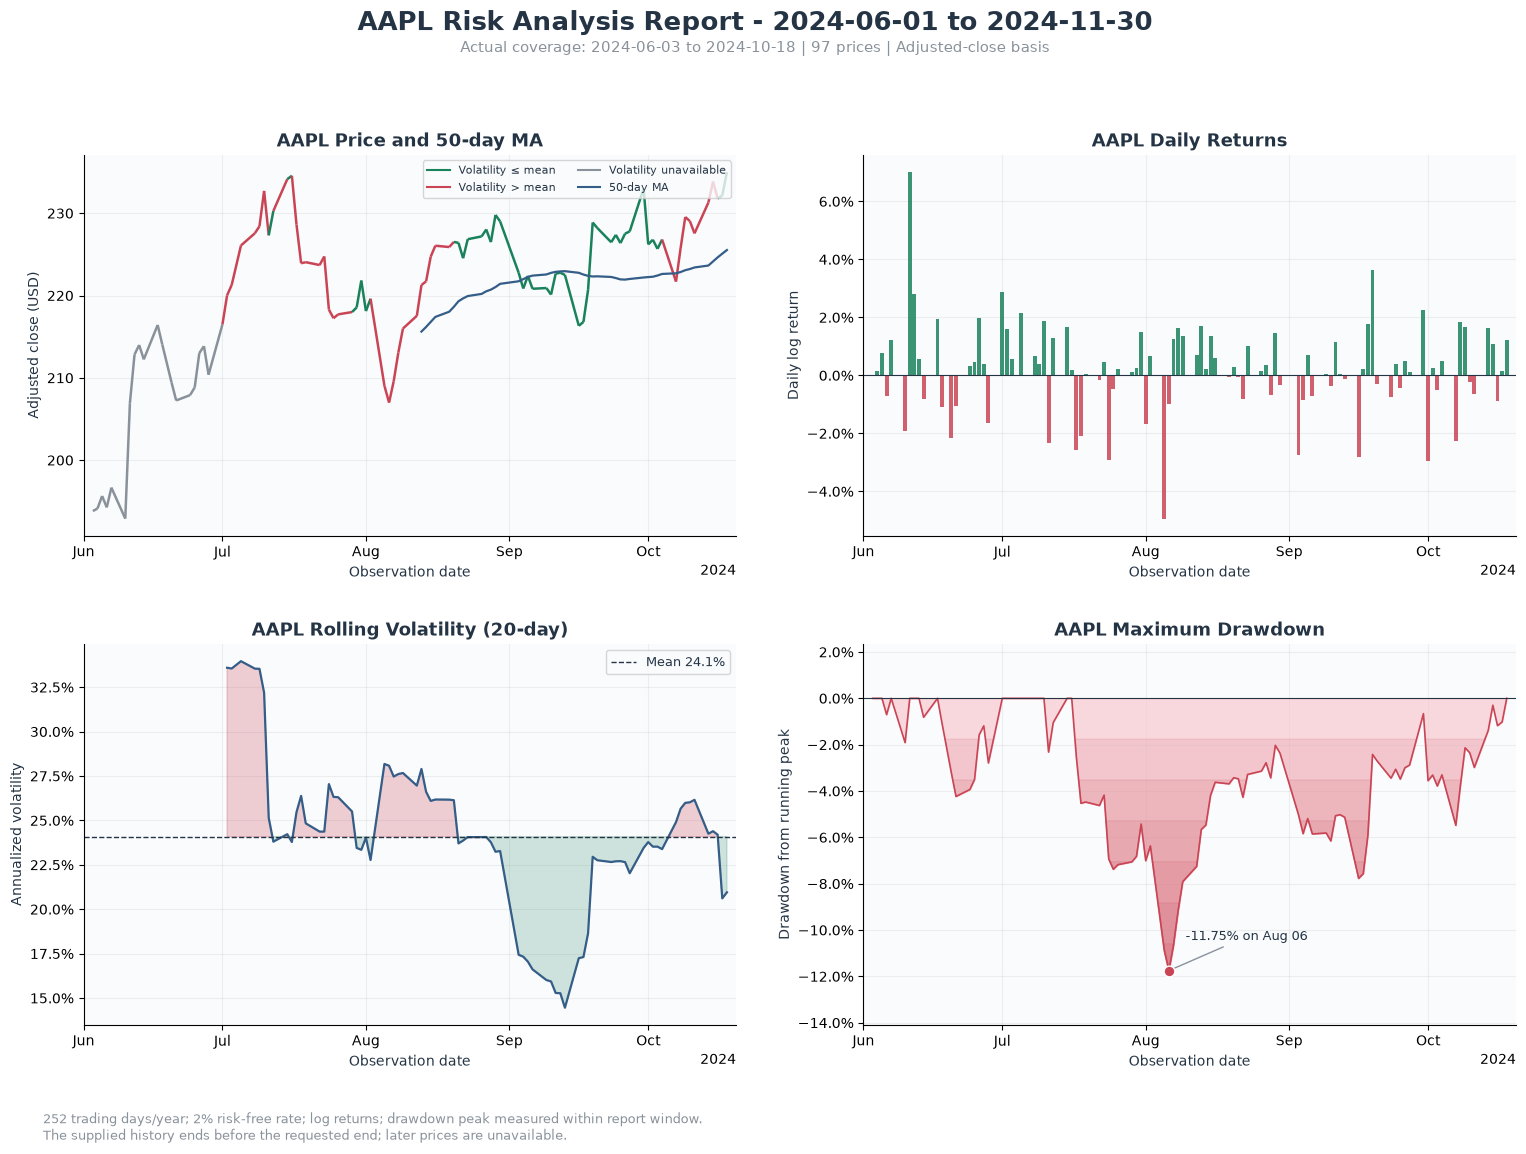

In [7]:
def plot_stock_report(frame, symbol, requested_start, requested_end, notes):
    """Create the required 16×12 four-panel report, preserving missing rolling estimates."""
    with plt.rc_context({'font.size': 10, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
                         'axes.labelcolor': COLORS['ink'], 'text.color': COLORS['ink'],
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'figure.facecolor': 'white', 'axes.facecolor': '#fafbfd'}):
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        price_ax, return_ax, vol_ax, dd_ax = axes.ravel()
        dates = frame.index
        x = mdates.date2num(dates.to_pydatetime())
        prices = frame['adj_close'].to_numpy(dtype=float)
        vol = frame['rolling_volatility']
        mean_vol = vol.mean()
        segment_colors = np.where(vol.isna(), COLORS['gray'],
                                  np.where(vol.gt(mean_vol), COLORS['red'], COLORS['green']))
        if len(frame) >= 2:
            points = np.column_stack([x, prices])
            segments = np.stack([points[:-1], points[1:]], axis=1)
            price_ax.add_collection(LineCollection(segments, colors=segment_colors[1:], linewidths=1.8))
            price_ax.update_datalim(points)
            price_ax.autoscale_view()
        else:
            price_ax.scatter(dates, prices, color=COLORS['gray'], s=35)
        price_ax.plot(dates, frame['moving_average_50'], color=COLORS['blue'], linewidth=1.6)
        price_ax.set(title=f'{symbol} Price and 50-day MA', ylabel='Adjusted close (USD)')
        price_ax.legend(handles=[
            Line2D([0], [0], color=COLORS['green'], label='Volatility ≤ mean'),
            Line2D([0], [0], color=COLORS['red'], label='Volatility > mean'),
            Line2D([0], [0], color=COLORS['gray'], label='Volatility unavailable'),
            Line2D([0], [0], color=COLORS['blue'], label='50-day MA')
        ], fontsize=8, loc='best', ncols=2)
        if frame['moving_average_50'].notna().sum() == 0:
            price_ax.text(.02, .03, '50-day MA unavailable: fewer than 50 prices', transform=price_ax.transAxes,
                          fontsize=9, color=COLORS['gray'])

        returns = frame['log_return'].dropna()
        return_colors = np.where(returns.gt(0), COLORS['green'],
                                 np.where(returns.lt(0), COLORS['red'], COLORS['gray']))
        return_ax.bar(returns.index, returns.to_numpy(), width=.85, color=return_colors, alpha=.85)
        return_ax.axhline(0, color=COLORS['ink'], linewidth=.8)
        return_ax.set(title=f'{symbol} Daily Returns', ylabel='Daily log return')
        return_ax.yaxis.set_major_formatter(PercentFormatter(1))
        if returns.empty:
            return_ax.text(.5, .5, 'No daily return available', transform=return_ax.transAxes, ha='center')

        vol_values = vol.to_numpy(dtype=float)
        vol_ax.plot(dates, vol_values, color=COLORS['blue'], linewidth=1.6)
        if np.isfinite(mean_vol):
            vol_ax.axhline(mean_vol, color=COLORS['ink'], linestyle='--', linewidth=1,
                           label=f'Mean {mean_vol:.1%}')
            vol_ax.fill_between(dates, vol_values, mean_vol, where=vol_values > mean_vol,
                                color=COLORS['red'], alpha=.25, interpolate=True)
            vol_ax.fill_between(dates, vol_values, mean_vol, where=vol_values < mean_vol,
                                color=COLORS['green'], alpha=.2, interpolate=True)
            vol_ax.legend(fontsize=9)
        else:
            vol_ax.text(.5, .5, '20-return estimate unavailable: need 21 prices',
                        transform=vol_ax.transAxes, ha='center', color=COLORS['gray'])
        vol_ax.set(title=f'{symbol} Rolling Volatility (20-day)', ylabel='Annualized volatility')
        vol_ax.yaxis.set_major_formatter(PercentFormatter(1))

        drawdown = frame['drawdown']
        dd_values = drawdown.to_numpy(dtype=float)
        dd_ax.fill_between(dates, dd_values, 0, color=COLORS['pink'], alpha=.65)
        worst = float(drawdown.min())
        if worst < 0:
            for fraction in np.linspace(.15, .9, 6):
                level = worst * fraction
                dd_ax.fill_between(dates, dd_values, level, where=dd_values < level,
                                   color=COLORS['red'], alpha=.12, interpolate=True)
        dd_ax.plot(dates, dd_values, color=COLORS['red'], linewidth=1.2)
        worst_date = drawdown.idxmin()
        dd_ax.scatter([worst_date], [worst], color=COLORS['red'], edgecolor='white', s=60, zorder=5)
        label_on_left = worst_date > dates.min() + (dates.max() - dates.min()) * .6
        dd_ax.annotate(f'{worst:.2%} on {worst_date:%b %d}', xy=(worst_date, worst),
                       xytext=(-12 if label_on_left else 12, 22), textcoords='offset points',
                       ha='right' if label_on_left else 'left', fontsize=9,
                       arrowprops={'arrowstyle': '-', 'color': COLORS['gray']})
        dd_ax.axhline(0, color=COLORS['ink'], linewidth=.8)
        dd_ax.set(title=f'{symbol} Maximum Drawdown', ylabel='Drawdown from running peak')
        dd_ax.yaxis.set_major_formatter(PercentFormatter(1))
        dd_ax.margins(y=.2)
        for ax in axes.ravel():
            ax.grid(True, alpha=.18)
            ax.set_axisbelow(True)
            ax.set_xlabel('Observation date')
            locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
            ax.xaxis.set_major_locator(locator)
            ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
            ax.margins(x=.02)
        # Align all panels to the actual observed window, including short-history reports.
        if len(frame) > 1:
            for ax in axes.ravel():
                ax.set_xlim(dates.min() - pd.Timedelta(days=2), dates.max() + pd.Timedelta(days=2))
        fig.suptitle(f'{symbol} Risk Analysis Report - {requested_start} to {requested_end}',
                     fontsize=19, fontweight='bold', y=.97)
        subtitle = f'Actual coverage: {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d} | {len(frame):,} prices | Adjusted-close basis'
        fig.text(.5, .935, subtitle, ha='center', fontsize=11, color=COLORS['gray'])
        footer = '252 trading days/year; 2% risk-free rate; log returns; drawdown peak measured within report window.'
        if notes:
            footer += '\n' + ' '.join(notes)
        fig.text(.055, .025, footer, ha='left', va='bottom', fontsize=9, color=COLORS['gray'], wrap=True)
        fig.tight_layout(rect=(.025, .075, .985, .915), h_pad=3, w_pad=3)
        return fig

figure = plot_stock_report(analysis, ticker, start_date, end_date, coverage_notes)
plt.show()
plt.close(figure)

## 2.5 Summary statistics
Total return is `last adjusted close / first adjusted close − 1`.
Annualized return compounds the observed log returns using `exp(sum(log returns) × 252 / n) − 1`.
Whole-period annualized volatility uses **all** defined daily returns; it is distinct from the mean
20-return rolling volatility used for chart coloring and the later portfolio dashboard.
Best/worst days and up/down averages below are log returns. Positive days include zero-return days
in the denominator. An empty up/down subset or undefined ratio displays `N/A`.

In [8]:
summary_table = pd.DataFrame([
    {'Metric': name, 'Value': ('N/A' if not np.isfinite(value)
                              else f'{value:.2f}' if name == 'Sharpe Ratio'
                              else f'{value:+.2%}' if name in ['Total Return', 'Annualized Return', 'Best Day', 'Worst Day', 'Average Up Day', 'Average Down Day']
                              else f'{value:.2%}')}
    for name, value in summary_metrics.items()
])
display(summary_table.set_index('Metric'))

,Value
Metric,
Total Return,+21.25%
Annualized Return,+65.84%
Annualized Volatility,25.45%
Sharpe Ratio,1.91
Maximum Drawdown,-11.75%
Best Day,+7.01%
Worst Day,-4.94%
Positive Days,62.50%
Average Up Day,+1.09%


### Named results for later batch collection
Scrapbook stores the following named output inside the executed notebook. The later runner can
collect the exact metrics from successful reports without parsing printed tables or recalculating
with a different return convention. Numeric metrics remain fractions; unavailable values become `None`.
Actual coverage accompanies the requested window so shorter histories can be disclosed in comparisons.

In [9]:
def finite_or_none(value):
    """Convert a scalar to a JSON-friendly float, or None when a metric is unavailable."""
    return float(value) if np.isfinite(value) else None

report_metrics = {
    'ticker': ticker,
    'start_date': start_date,
    'end_date': end_date,
    'actual_start_date': actual_start,
    'actual_end_date': actual_end,
    'n_prices': len(analysis),
    'n_returns': int(analysis.log_return.notna().sum()),
    'avg_daily_return': finite_or_none(analysis.log_return.mean()),
    'avg_volatility': finite_or_none(mean_rolling_volatility),
    'max_drawdown': finite_or_none(summary_metrics['Maximum Drawdown']),
    'sharpe_ratio': finite_or_none(summary_metrics['Sharpe Ratio']),
    'total_return': finite_or_none(summary_metrics['Total Return']),
    'annualized_return': finite_or_none(summary_metrics['Annualized Return']),
    'annualized_volatility': finite_or_none(summary_metrics['Annualized Volatility']),
    'coverage_notes': coverage_notes
}
sb.glue('report_metrics', report_metrics)
print('Named report_metrics saved for later batch collection.')

Named report_metrics saved for later batch collection.
